In [2]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [3]:
df = pd.read_csv("quebec_housing_sales_v2.csv")


In [4]:
df.head()

,property_id,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqft,lot_size_sqft,year_built,renovation_year,garage,basement,sale_year,sale_price
0,1,Châteauguay,Centre-Ville,Townhouse,3,2,1160,2304.0,2022,NaN,Yes,No,2024,326000
1,2,Trois-Rivières,Cap-de-la-Madeleine,Duplex,4,4,1807,5869.0,2006,2024.0,No,Yes,2025,444000
2,3,Lévis,Charny,Townhouse,3,1,803,3387.0,1989,NaN,Yes,Yes,2025,273000
3,4,Laval,Fabreville,Single Family,3,3,1083,11417.0,1972,2016.0,Yes,Yes,2023,465000
4,5,Longueuil,Greenfield Park,Condo,2,2,714,NaN,1997,2010.0,Yes,No,2022,371000


In [5]:
# 1. CONTINUOUS VARIABLES SUMMARY
continuous_vars = [
    'bedrooms',
    'bathrooms',
    'living_area_sqft',
    'lot_size_sqft',
    'year_built',
    'renovation_year',
    'sale_price', 
    'sale_year',
]
cont_summary = []

for col in continuous_vars:
    s = df[col]
    total = len(s)
    
    # Calculate missing percentage simply
    missing_count = s.isna().sum()
    missing_pct = round((missing_count / total) * 100, 2)
    
    cont_summary.append({
        'Feature': col,
        'Total Count': total,
        'Missing (%)': missing_pct,
        'Cardinality': len(s.unique()),
        'Min': s.min(),
        'Max': s.max(),
        'Q1': s.quantile(0.25),
        'Q3': s.quantile(0.75),
        'Mean': round(s.mean(), 2),
        'Median': s.median(),
        'Std Dev': round(s.std(), 2)
    })

df_cont_summary = pd.DataFrame(cont_summary)
print(df_cont_summary)

            Feature  Total Count  Missing (%)  Cardinality       Min  \
0          bedrooms         5000         0.00            8       1.0   
1         bathrooms         5000         0.00            6       1.0   
2  living_area_sqft         5000         0.00         1670     469.0   
3     lot_size_sqft         5000        24.22         3145    1570.0   
4        year_built         5000         0.00          124    1900.0   
5   renovation_year         5000        68.16           22    2005.0   
6        sale_price         5000         0.00          803  114000.0   
7         sale_year         5000         0.00            5    2021.0   

         Max        Q1        Q3       Mean    Median    Std Dev  
0        8.0       2.0       4.0       3.49       3.0       1.36  
1        6.0       2.0       3.0       2.33       2.0       0.97  
2     2967.0     915.0    1650.0    1313.69    1273.0     472.11  
3    14834.0    4086.0    8005.0    6257.15    5767.0    2811.43  
4     2023.0    

In [6]:
# 2. CATEGORICAL VARIABLES SUMMARY
categorical_vars = [
    'city',
    'neighborhood',
    'property_type',
    'garage',
    'basement',
]
cat_summary = []

for col in categorical_vars:
    s = df[col]
    vc = s.value_counts(dropna=True)
    
    total = len(s)
    
    # Missing percentage
    missing_pct = round((s.isna().sum() / total) * 100, 2)
    
    # Cardinality (number of unique categories)
    unique_count = len(vc)
    
    # Mode 1 stats
    mode1_val = vc.index[0]
    mode1_freq = vc.values[0]
    mode1_pct = round((mode1_freq / total) * 100, 2)
    
    # Mode 2 stats
    mode2_val = None
    mode2_freq = 0
    mode2_pct = 0.0
    
    if unique_count > 1:
        mode2_val = vc.index[1]
        mode2_freq = vc.values[1]
        mode2_pct = round((mode2_freq / total) * 100, 2)
    
    cat_summary.append({
        'Feature': col,
        'Total Count': total,
        'Missing (%)': missing_pct,
        'Cardinality': unique_count,
        'Mode 1': mode1_val,
        'Mode 1 Freq': mode1_freq,
        'Mode 1 (%)': mode1_pct,
        'Mode 2': mode2_val,
        'Mode 2 Freq': mode2_freq,
        'Mode 2 (%)': mode2_pct
    })

df_cat_summary = pd.DataFrame(cat_summary)
print(df_cat_summary)

         Feature  Total Count  Missing (%)  Cardinality         Mode 1  \
0           city         5000          0.0           32       Montréal   
1   neighborhood         5000          0.0           72   Centre-Ville   
2  property_type         5000          0.0            6  Single Family   
3         garage         5000          0.0            2            Yes   
4       basement         5000          0.0            2            Yes   

   Mode 1 Freq  Mode 1 (%)       Mode 2  Mode 2 Freq  Mode 2 (%)  
0          919       18.38       Québec          529       10.58  
1          625       12.50  West Island          133        2.66  
2         2254       45.08        Condo         1211       24.22  
3         3476       69.52           No         1524       30.48  
4         3032       60.64           No         1968       39.36  


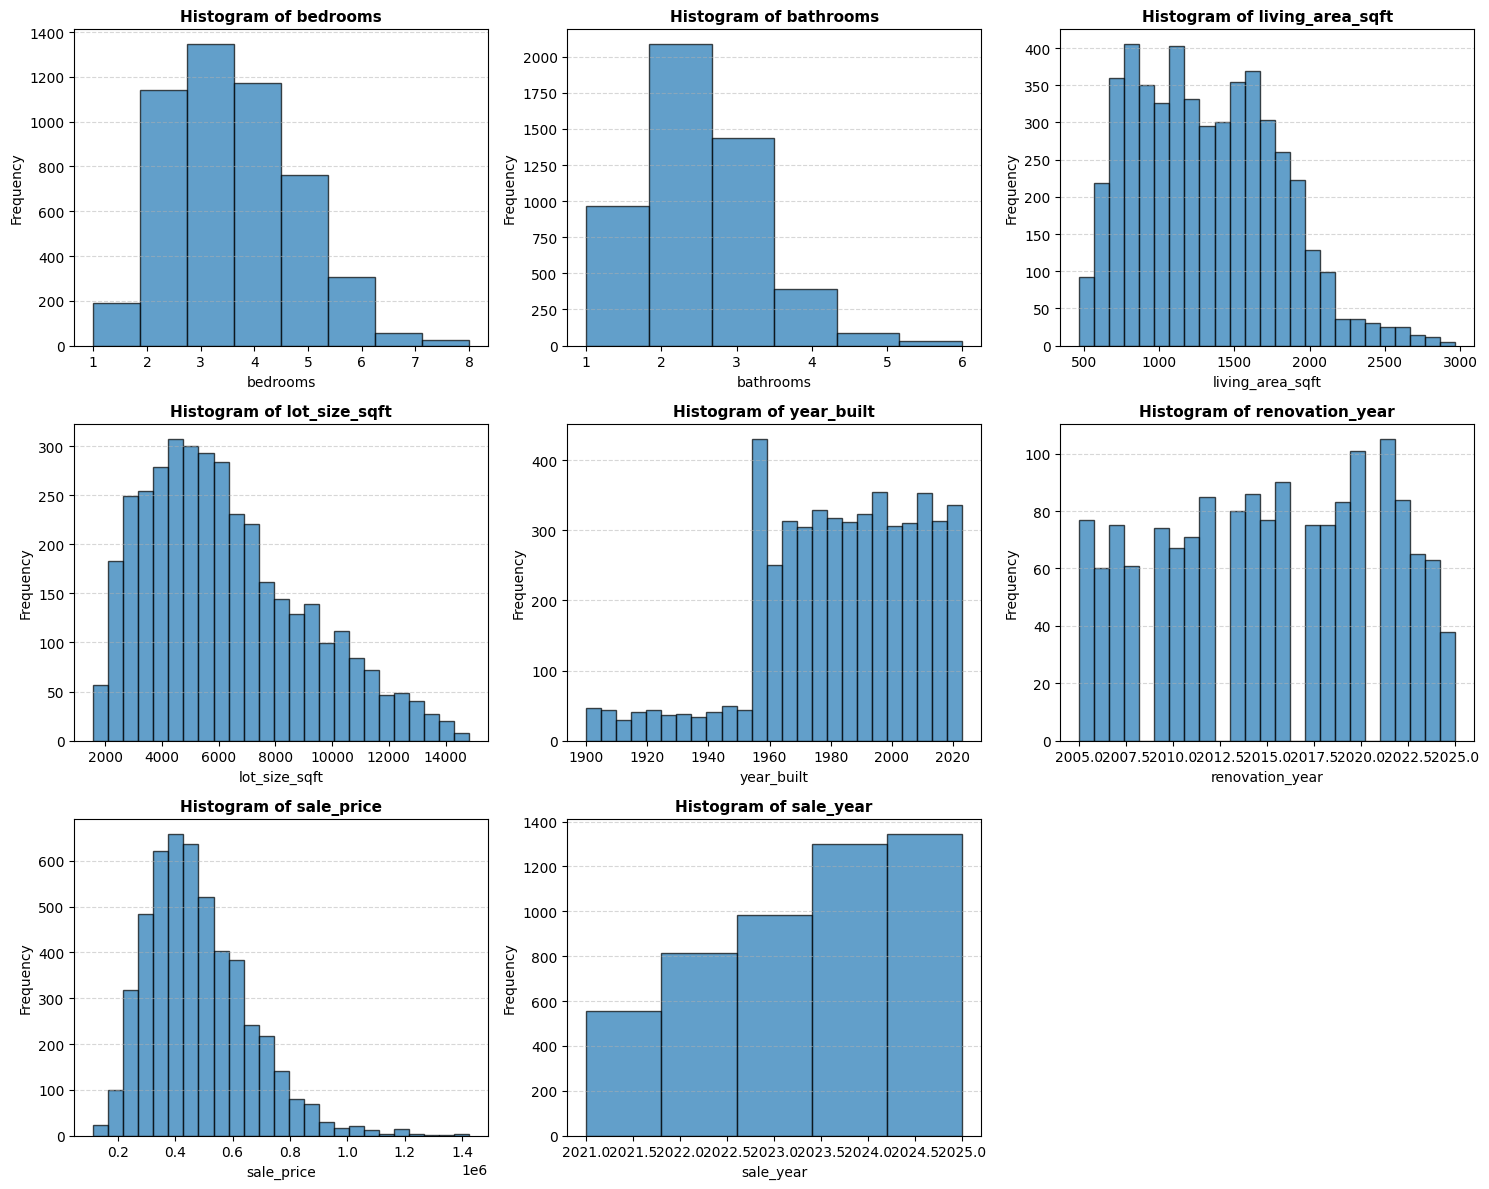

In [7]:
plt.figure(figsize=(15, 12))

for i, col in enumerate(continuous_vars, 1):
  plt.subplot(3, 3, i)
  data_to_plot = df[col].dropna()

  # Set bins dynamically based on discrete vs continuous data
  unique_vals = data_to_plot.nunique()
  bins = unique_vals if unique_vals <= 10 else 25

  plt.hist(data_to_plot, bins=bins, edgecolor='black', alpha=0.7)
  plt.title(f'Histogram of {col}', fontsize=11, fontweight='bold')
  plt.xlabel(col)
  plt.ylabel('Frequency')
  plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

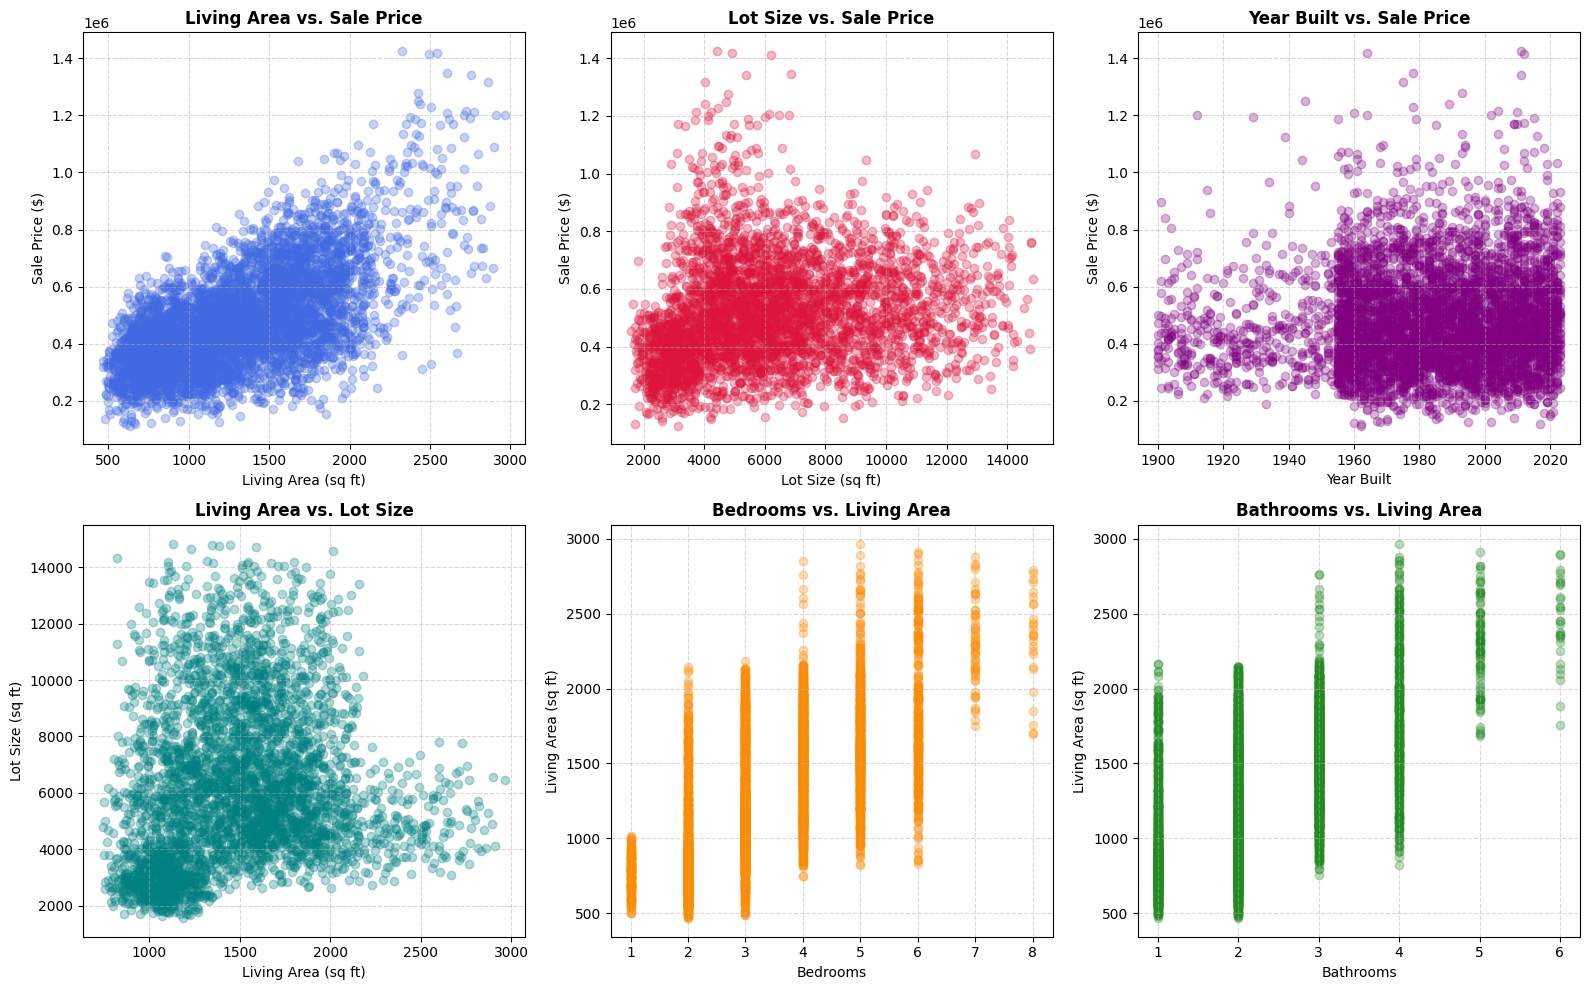

In [8]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# 1. Living Area vs Sale Price
axes[0, 0].scatter(
    df['living_area_sqft'], df['sale_price'], alpha=0.3, color='royalblue'
)
axes[0, 0].set_title('Living Area vs. Sale Price', fontweight='bold')
axes[0, 0].set_xlabel('Living Area (sq ft)')
axes[0, 0].set_ylabel('Sale Price ($)')
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# 2. Lot Size vs Sale Price
axes[0, 1].scatter(
    df['lot_size_sqft'], df['sale_price'], alpha=0.3, color='crimson'
)
axes[0, 1].set_title('Lot Size vs. Sale Price', fontweight='bold')
axes[0, 1].set_xlabel('Lot Size (sq ft)')
axes[0, 1].set_ylabel('Sale Price ($)')
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# 3. Year Built vs Sale Price
axes[0, 2].scatter(
    df['year_built'], df['sale_price'], alpha=0.3, color='purple'
)
axes[0, 2].set_title('Year Built vs. Sale Price', fontweight='bold')
axes[0, 2].set_xlabel('Year Built')
axes[0, 2].set_ylabel('Sale Price ($)')
axes[0, 2].grid(True, linestyle='--', alpha=0.5)

# 4. Living Area vs Lot Size
axes[1, 0].scatter(
    df['living_area_sqft'], df['lot_size_sqft'], alpha=0.3, color='teal'
)
axes[1, 0].set_title('Living Area vs. Lot Size', fontweight='bold')
axes[1, 0].set_xlabel('Living Area (sq ft)')
axes[1, 0].set_ylabel('Lot Size (sq ft)')
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

# 5. Bedrooms vs Living Area
axes[1, 1].scatter(
    df['bedrooms'], df['living_area_sqft'], alpha=0.3, color='darkorange'
)
axes[1, 1].set_title('Bedrooms vs. Living Area', fontweight='bold')
axes[1, 1].set_xlabel('Bedrooms')
axes[1, 1].set_ylabel('Living Area (sq ft)')
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

# 6. Bathrooms vs Living Area
axes[1, 2].scatter(
    df['bathrooms'], df['living_area_sqft'], alpha=0.3, color='forestgreen'
)
axes[1, 2].set_title('Bathrooms vs. Living Area', fontweight='bold')
axes[1, 2].set_xlabel('Bathrooms')
axes[1, 2].set_ylabel('Living Area (sq ft)')
axes[1, 2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

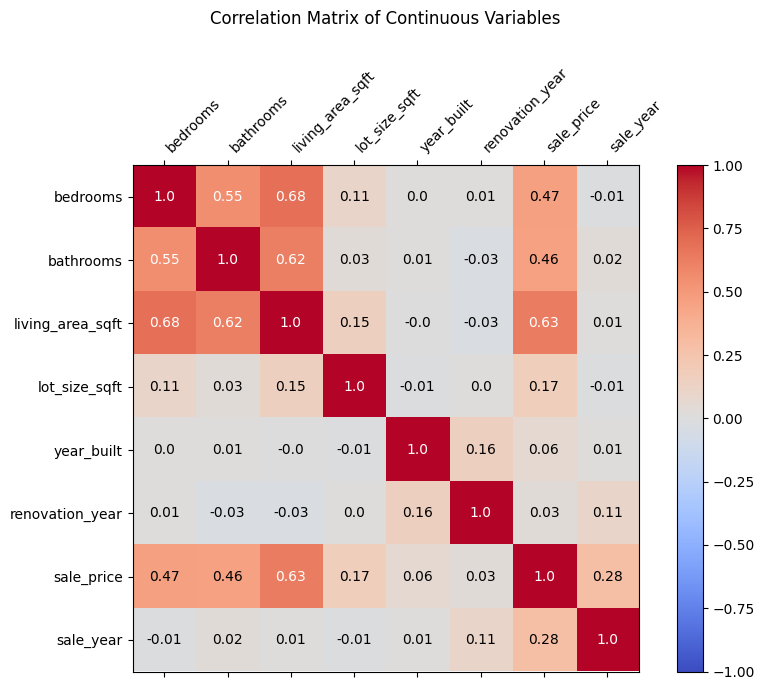

In [9]:
# Continuous variables for correlation matrix
num_cols = [
    'bedrooms',
    'bathrooms',
    'living_area_sqft',
    'lot_size_sqft',
    'year_built',
    'renovation_year',
    'sale_price',
    'sale_year',
]

corr_matrix = df[num_cols].corr()
corr_values = corr_matrix.values

# Plot heatmap
fig, ax = plt.subplots(figsize=(9, 7))
cax = ax.matshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax)

ax.set_xticks(range(len(num_cols)))
ax.set_yticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45, ha='left')
ax.set_yticklabels(num_cols)

# Loop using plain array indexing and simple logic
for i in range(len(num_cols)):
  for j in range(len(num_cols)):
    val = corr_values[i, j]

    text_color = 'black'
    if abs(val) > 0.5:
      text_color = 'white'

    ax.text(j, i, round(val, 2), ha='center', va='center', color=text_color)

plt.title('Correlation Matrix of Continuous Variables', pad=30)
plt.tight_layout()
plt.show()

In [10]:
df['is_renovated'] = [
    1 if (r == r and r is not None and r > 0) else 0
    for r in df['renovation_year']
]
df['renovation_year_clean'] = [
    0.0 if (r != r or r is None) else float(r) for r in df['renovation_year']
]
df['house_age'] = df['sale_year'] - df['year_built']

y = df['sale_price'].values.reshape(-1, 1)
X_df = df.drop(
    columns=['property_id', 'sale_price', 'renovation_year'], errors='ignore'
)

# 2. Train/Test Split (80% train, 20% test using iloc)
np.random.seed(42)
n = len(df)
train_size = int(0.8 * n)

shuffled = np.random.permutation(n)
train_idx, test_idx = shuffled[:train_size], shuffled[train_size:]

X_train_df = X_df.iloc[train_idx].copy()
X_test_df = X_df.iloc[test_idx].copy()
y_train, y_test = y[train_idx], y[test_idx]

# 3. Handle Missing Values & Outliers (Built-in stats)
lot_median = X_train_df['lot_size_sqft'].median()
X_train_df['lot_size_sqft'] = X_train_df['lot_size_sqft'].fillna(lot_median)
X_test_df['lot_size_sqft'] = X_test_df['lot_size_sqft'].fillna(lot_median)

q1_liv, q3_liv = (
    X_train_df['living_area_sqft'].quantile(0.25),
    X_train_df['living_area_sqft'].quantile(0.75),
)
iqr_liv = q3_liv - q1_liv

q1_lot, q3_lot = (
    X_train_df['lot_size_sqft'].quantile(0.25),
    X_train_df['lot_size_sqft'].quantile(0.75),
)
iqr_lot = q3_lot - q1_lot

min_liv, max_liv = q1_liv - 1.5 * iqr_liv, q3_liv + 1.5 * iqr_liv
min_lot, max_lot = q1_lot - 1.5 * iqr_lot, q3_lot + 1.5 * iqr_lot

X_train_df['living_area_sqft'] = np.clip(
    X_train_df['living_area_sqft'], min_liv, max_liv
)
X_test_df['living_area_sqft'] = np.clip(
    X_test_df['living_area_sqft'], min_liv, max_liv
)

X_train_df['lot_size_sqft'] = np.clip(
    X_train_df['lot_size_sqft'], min_lot, max_lot
)
X_test_df['lot_size_sqft'] = np.clip(
    X_test_df['lot_size_sqft'], min_lot, max_lot
)

# 4. One-Hot Encoding (No f-strings, split with iloc)
cat_cols = ['city', 'neighborhood', 'property_type', 'garage', 'basement']
combined = pd.concat([X_train_df, X_test_df], axis=0)

for col in cat_cols:
  cats = sorted(combined[col].unique())[1:]
  for c in cats:
    col_name = str(col) + '_' + str(c)
    combined[col_name] = [1 if val == c else 0 for val in combined[col]]

combined = combined.drop(columns=cat_cols)

X_train_encoded = combined.iloc[:train_size].copy()
X_test_encoded = combined.iloc[train_size:].copy()

# 5. Standardization (Built-in mean and std)
scale_cols = [
    'bedrooms',
    'bathrooms',
    'living_area_sqft',
    'lot_size_sqft',
    'year_built',
    'renovation_year_clean',
    'house_age',
    'sale_year',
]

train_means = X_train_encoded[scale_cols].mean()
train_stds = X_train_encoded[scale_cols].std()

X_train_encoded[scale_cols] = (
    X_train_encoded[scale_cols] - train_means
) / train_stds
X_test_encoded[scale_cols] = (
    X_test_encoded[scale_cols] - train_means
) / train_stds

C:\Users\User\AppData\Local\Temp\ipykernel_12984\4260147686.py:69: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  combined[col_name] = [1 if val == c else 0 for val in combined[col]]


In [ ]:

# 3.a.i. METHOD OF LEAST SQUARES (OLS)

def fit_linear_regression_ols(X, y):
  #w = (X^T * X)^(-1) * X^T * y
  
  # Add bias (column of 1s) as the first column
  n_samples = X.shape[0]
  bias_column = np.ones((n_samples, 1))
  X_b = np.hstack([bias_column, X])

  w_ols = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y

  return w_ols



# 3.a.ii. GRADIENT DESCENT METHOD

def fit_linear_regression_gd(X, y, learning_rate=0.01, iterations=1000):

  #Gradient: (2 / n) * X_b^T * (X_b * w - y)

  # Add bias (column of 1s) as the first column
  n_samples, n_features = X.shape
  bias_column = np.ones((n_samples, 1))
  X_b = np.hstack([bias_column, X])

  # Initialize weights with zeros (shape: [num_features + 1, 1])
  w_gd = np.zeros((n_features + 1, 1))

  # Gradient Descent Loop
  for step in range(iterations):
    # Compute predictions: y_pred = X_b @ w
    predictions = X_b @ w_gd

    # Compute errors and gradient vector
    errors = predictions - y
    gradient = (2 / n_samples) * (X_b.T @ errors)

    # Update weights
    w_gd = w_gd - (learning_rate * gradient)
  


  return w_gd

In [12]:
# Drop redundant linear dependent column to fix singularity
X_train_clean = X_train_encoded.drop(columns=['house_age'], errors='ignore')

# Convert DataFrames to NumPy arrays for calculation
X_train_mat = X_train_clean.values
y_train_mat = y_train.reshape(-1, 1)

# 1. Fit using Least Squares (OLS)
weights_ols = fit_linear_regression_ols(X_train_mat, y_train_mat)

# 2. Fit using Gradient Descent
weights_gd = fit_linear_regression_gd(
    X_train_mat, y_train_mat, learning_rate=0.05, iterations=2000
)

# Print first few coefficients for comparison using .item() to avoid deprecation warnings
print('--- Least Squares (OLS) Coefficients ---')
print('Intercept (w0):', weights_ols[0].item())
print('First 3 Feature Weights:', weights_ols[1:4].flatten())

print('\n--- Gradient Descent Coefficients ---')
print('Intercept (w0):', weights_gd[0].item())
print('First 3 Feature Weights:', weights_gd[1:4].flatten())

--- Least Squares (OLS) Coefficients ---
Intercept (w0): 752251.9345997768
First 3 Feature Weights: [ 9363.04423666 10226.09655142 93058.85665118]

--- Gradient Descent Coefficients ---
Intercept (w0): 366827.8979901539
First 3 Feature Weights: [ 8017.9574839   8013.95199854 89134.62157675]


In [13]:
# Align test set with clean training features
X_test_clean = X_test_encoded.drop(columns=['house_age'], errors='ignore')

# 1. Fit models using both implemented methods
weights_ols = fit_linear_regression_ols(X_train_mat, y_train_mat)
weights_gd = fit_linear_regression_gd(
    X_train_mat, y_train_mat, learning_rate=0.05, iterations=2000
)

# 2. Extract feature names (including Intercept w0)
feature_names = ['Intercept (w0)'] + list(X_train_clean.columns)

# 3. Create comparison DataFrame
comparison_df = pd.DataFrame({
    'Feature': feature_names,
    'OLS Coefficients': weights_ols.flatten(),
    'Gradient Descent Coefficients': weights_gd.flatten(),
})

# Calculate absolute difference for easy comparison
comparison_df['Absolute Difference'] = (
    comparison_df['OLS Coefficients']
    - comparison_df['Gradient Descent Coefficients']
).abs()

# Display full table
print(comparison_df.to_string(index=False))

                           Feature  OLS Coefficients  Gradient Descent Coefficients  Absolute Difference
                    Intercept (w0)      7.522519e+05                  366827.897990         3.854240e+05
                          bedrooms      9.363044e+03                    8017.957484         1.345087e+03
                         bathrooms      1.022610e+04                    8013.951999         2.212145e+03
                  living_area_sqft      9.305886e+04                   89134.621577         3.924235e+03
                     lot_size_sqft      1.137483e+04                   11754.074282         3.792465e+02
                        year_built      1.236494e+04                   12548.233614         1.832943e+02
                         sale_year      4.997453e+04                   50184.802568         2.102700e+02
                      is_renovated     -1.059197e+06                  100498.700224         1.159696e+06
             renovation_year_clean      5.065312e+05   

In [14]:


# 1. Compute Residuals & Variance
n_samples, n_features = X_train_mat.shape
X_b = np.hstack([np.ones((n_samples, 1)), X_train_mat])

predictions = X_b @ weights_ols
residuals = y_train_mat - predictions

degrees_of_freedom = n_samples - n_features - 1
residual_variance = (residuals.T @ residuals) / degrees_of_freedom

# 2. Covariance Matrix & Standard Errors
cov_matrix = residual_variance.item() * np.linalg.pinv(X_b.T @ X_b)
standard_errors = np.sqrt(np.diag(cov_matrix)).reshape(-1, 1)

# 3. Calculate t-statistics
t_stats = weights_ols / standard_errors


# 4. Manual p-value calculation using standard math.erf
def manual_p_value(t_array):
  p_vals = []
  for t in t_array.flatten():
    # CDF of Normal distribution using math.erf
    cdf = 0.5 * (1.0 + math.erf(abs(t) / math.sqrt(2.0)))
    p = 2.0 * (1.0 - cdf)
    p_vals.append(p)
  return np.array(p_vals).reshape(-1, 1)


p_values = manual_p_value(t_stats)

# 5. Build Summary Table
feature_names = ['Intercept (w0)'] + list(X_train_clean.columns)
stats_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': weights_ols.flatten(),
    'Std Error': standard_errors.flatten(),
    't-statistic': t_stats.flatten(),
    'p-value': p_values.flatten(),
    'Significant (alpha=0.05)': p_values.flatten() < 0.05,
})

print(stats_df.to_string(index=False))

                           Feature   Coefficient     Std Error  t-statistic      p-value  Significant (alpha=0.05)
                    Intercept (w0)  7.522519e+05 197671.964091     3.805557 1.414854e-04                      True
                          bedrooms  9.363044e+03   1666.070367     5.619837 1.911375e-08                      True
                         bathrooms  1.022610e+04   1518.288622     6.735278 1.636158e-11                      True
                  living_area_sqft  9.305886e+04   2117.857242    43.940099 0.000000e+00                      True
                     lot_size_sqft  1.137483e+04   1470.517311     7.735256 1.021405e-14                      True
                        year_built  1.236494e+04   1131.722264    10.925772 0.000000e+00                      True
                         sale_year  4.997453e+04   1036.997451    48.191567 0.000000e+00                      True
                      is_renovated -1.059197e+06 653698.570765    -1.620314 1.05

In [15]:
# Extract features that are NOT significant (p >= 0.05), ignoring Intercept
insignificant_cols = stats_df[
    (~stats_df['Significant (alpha=0.05)'])
    & (stats_df['Feature'] != 'Intercept (w0)')
]['Feature'].tolist()

print('Features removed due to p >= 0.05:', insignificant_cols)

# Modify dataset by dropping insignificant features
X_train_pruned = X_train_clean.drop(columns=insignificant_cols)
X_test_pruned = X_test_clean.drop(columns=insignificant_cols)

# Refit OLS with modified feature set
X_train_pruned_mat = X_train_pruned.values
weights_ols_modified = fit_linear_regression_ols(
    X_train_pruned_mat, y_train_mat
)

Features removed due to p >= 0.05: ['is_renovated', 'renovation_year_clean', 'city_Lévis', 'city_Québec', 'city_Rouyn-Noranda', 'city_Sherbrooke', 'neighborhood_Beauport', 'neighborhood_Bellefeuille', 'neighborhood_Cap-de-la-Madeleine', 'neighborhood_Centre-Ville', 'neighborhood_Charlesbourg', 'neighborhood_Charny', 'neighborhood_Fleurimont', 'neighborhood_Hochelaga-Maisonneuve', 'neighborhood_Iberville', 'neighborhood_Jonquière', 'neighborhood_LaSalle', 'neighborhood_Lachine', 'neighborhood_Lebourgneuf', 'neighborhood_Lennoxville', 'neighborhood_Limoilou', 'neighborhood_Lévis Centre', 'neighborhood_Mercier', 'neighborhood_NDG', 'neighborhood_Outremont', 'neighborhood_Plateau-Mont-Royal', 'neighborhood_Pointe-aux-Trembles', 'neighborhood_Rock Forest', 'neighborhood_Rosemont', 'neighborhood_Rouyn Centre', 'neighborhood_Saint-Charles', 'neighborhood_Saint-Léonard', 'neighborhood_Saint-Nicolas', 'neighborhood_Sainte-Foy', 'neighborhood_Sainte-Monique', 'neighborhood_Sillery', 'neighborhoo

In [16]:
# Prepare cleaned matrix after hypothesis testing pruning
X_mat_pruned = X_train_pruned.values
y_mat_pruned = y_train_mat.reshape(-1, 1)

# Set random seed for reproducibility and shuffle dataset indices
np.random.seed(42)
n_samples = len(X_mat_pruned)
k_folds = 5

indices = np.random.permutation(n_samples)
fold_sizes = np.full(k_folds, n_samples // k_folds, dtype=int)
fold_sizes[: n_samples % k_folds] += 1  # Distribute remainder evenly

# Generate fold index splits using iloc/slicing logic
folds = []
current_idx = 0
for fold_size in fold_sizes:
  start_idx = current_idx
  end_idx = current_idx + fold_size
  folds.append(indices[start_idx:end_idx])
  current_idx = end_idx

# Metrics storage
cv_mse_scores = []
cv_rmse_scores = []

# Cross-Validation Loop
for fold_idx in range(k_folds):
  # 1. Validation split for current fold
  val_indices = folds[fold_idx]

  # 2. Training split (all remaining folds concatenated)
  train_indices = np.hstack(
      [folds[i] for i in range(k_folds) if i != fold_idx]
  )

  # Extract train and validation sets
  X_cv_train, y_cv_train = (
      X_mat_pruned[train_indices],
      y_mat_pruned[train_indices],
  )
  X_cv_val, y_cv_val = X_mat_pruned[val_indices], y_mat_pruned[val_indices]

  # 3. Fit OLS model on cross-validation training fold
  w_cv = fit_linear_regression_ols(X_cv_train, y_cv_train)

  # 4. Predict on validation fold (add bias column of 1s)
  X_cv_val_b = np.hstack([np.ones((len(X_cv_val), 1)), X_cv_val])
  val_preds = X_cv_val_b @ w_cv

  # 5. Compute Error Metrics manually
  val_mse = sum((y_cv_val - val_preds) ** 2)[0] / len(y_cv_val)
  val_rmse = val_mse**0.5

  cv_mse_scores.append(val_mse)
  cv_rmse_scores.append(val_rmse)

# Build Results Summary Table
cv_results = pd.DataFrame({
    'Fold': [
        'Fold 1',
        'Fold 2',
        'Fold 3',
        'Fold 4',
        'Fold 5',
        'Average / Overall',
    ],
    'MSE': cv_mse_scores + [sum(cv_mse_scores) / k_folds],
    'RMSE': cv_rmse_scores + [sum(cv_rmse_scores) / k_folds],
})

print(cv_results.to_string(index=False))

             Fold          MSE         RMSE
           Fold 1 4.738161e+09 68834.303542
           Fold 2 4.370986e+09 66113.430840
           Fold 3 4.496116e+09 67053.085428
           Fold 4 4.311501e+09 65662.019336
           Fold 5 4.291420e+09 65508.933140
Average / Overall 4.441637e+09 66634.354457


           Model Case     Mean RMSE  Std Dev (RMSE)
  i. Significant Only  66634.354457     1369.167790
ii. Top 3 Significant 128306.747385     2911.514703
   iii. All Variables  65593.749465     1251.107189


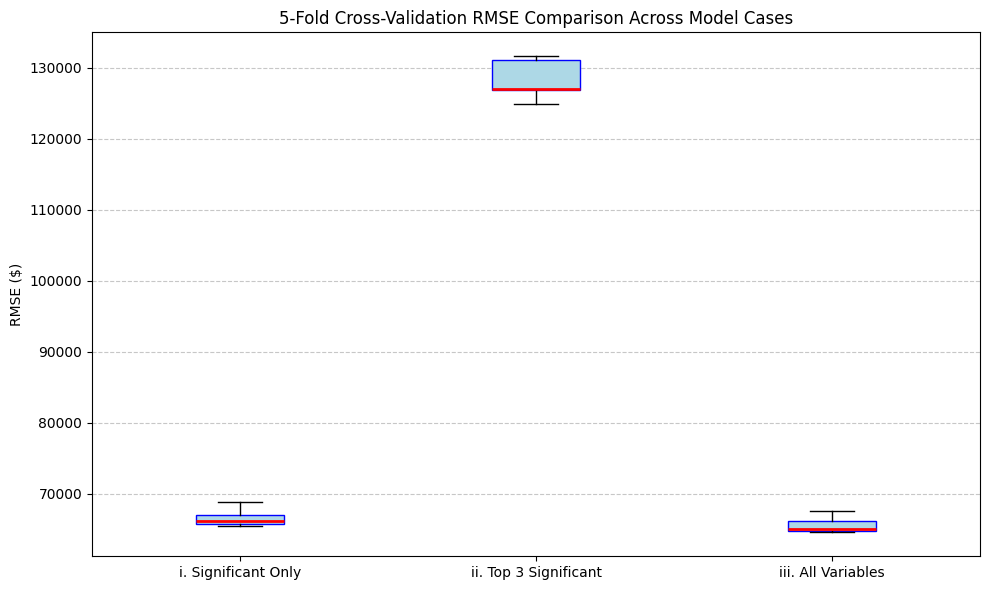

In [17]:
# 1. Custom OLS Evaluator
def fit_and_eval_ols(X_train, y_train, X_val, y_val):
  n_train = X_train.shape[0]
  n_val = X_val.shape[0]

  # Add bias terms
  X_tr_b = np.hstack([np.ones((n_train, 1)), X_train])
  X_va_b = np.hstack([np.ones((n_val, 1)), X_val])

  # Calculate OLS weights using pseudo-inverse
  w = np.linalg.pinv(X_tr_b.T @ X_tr_b) @ X_tr_b.T @ y_train

  # Predictions and MSE
  preds = X_va_b @ w
  mse = np.mean((y_val - preds) ** 2)
  rmse = math.sqrt(mse)
  return mse, rmse


# 2. Variable Group Definitions based on your previous hypothesis testing
# Top 3 most significant variables (by highest |t-stat|: living_area_sqft, city, lot_size_sqft)
top_3_vars = ['living_area_sqft', 'lot_size_sqft', 'sale_year']

# Significant variables (p < 0.05)
sig_vars = [col for col in X_train_pruned.columns]

# All possible variables (excluding house_age to prevent perfect collinearity)
all_vars = [col for col in X_train_clean.columns]

model_cases = {
    'i. Significant Only': sig_vars,
    'ii. Top 3 Significant': top_3_vars,
    'iii. All Variables': all_vars,
}

# 3. Setup K-Fold Cross Validation (K=5)
np.random.seed(42)
k = 5
n_samples = len(y_train_mat)
shuffled_idx = np.random.permutation(n_samples)
fold_size = n_samples // k

cv_results = {}

for case_name, var_list in model_cases.items():
  X_data = X_train_clean[var_list].values
  rmse_list = []

  for fold in range(k):
    val_idx = shuffled_idx[fold * fold_size : (fold + 1) * fold_size]
    train_idx = np.setdiff1d(shuffled_idx, val_idx)

    X_tr, y_tr = X_data[train_idx], y_train_mat[train_idx]
    X_va, y_va = X_data[val_idx], y_train_mat[val_idx]

    _, rmse = fit_and_eval_ols(X_tr, y_tr, X_va, y_va)
    rmse_list.append(rmse)

  cv_results[case_name] = rmse_list

# 4. Calculate Summary Metrics (Mean & Std)
summary_data = []
for case_name, scores in cv_results.items():
  mean_rmse = np.mean(scores)
  std_rmse = np.std(scores, ddof=1)
  summary_data.append({
      'Model Case': case_name,
      'Mean RMSE': mean_rmse,
      'Std Dev (RMSE)': std_rmse,
  })

metrics_df = pd.DataFrame(summary_data)
print(metrics_df.to_string(index=False))

plt.figure(figsize=(10, 6))
plt.boxplot(
    [cv_results[key] for key in cv_results],
    tick_labels=list(cv_results.keys()),  # Updated to fix Matplotlib deprecation warning
    patch_artist=True,
    boxprops=dict(facecolor='lightblue', color='blue'),
    medianprops=dict(color='red', linewidth=2),
)
plt.title('5-Fold Cross-Validation RMSE Comparison Across Model Cases')
plt.ylabel('RMSE ($)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

=== HOLD-OUT TEST DATA PERFORMANCE ===
                Model Configuration      MAE ($)          MSE     RMSE ($)  R² Score
           All Variables (Case iii) 49161.138198 4.107915e+09 64093.017046  0.864628
Significant Variables Only (Case i) 49344.573608 4.171955e+09 64590.670139  0.862518


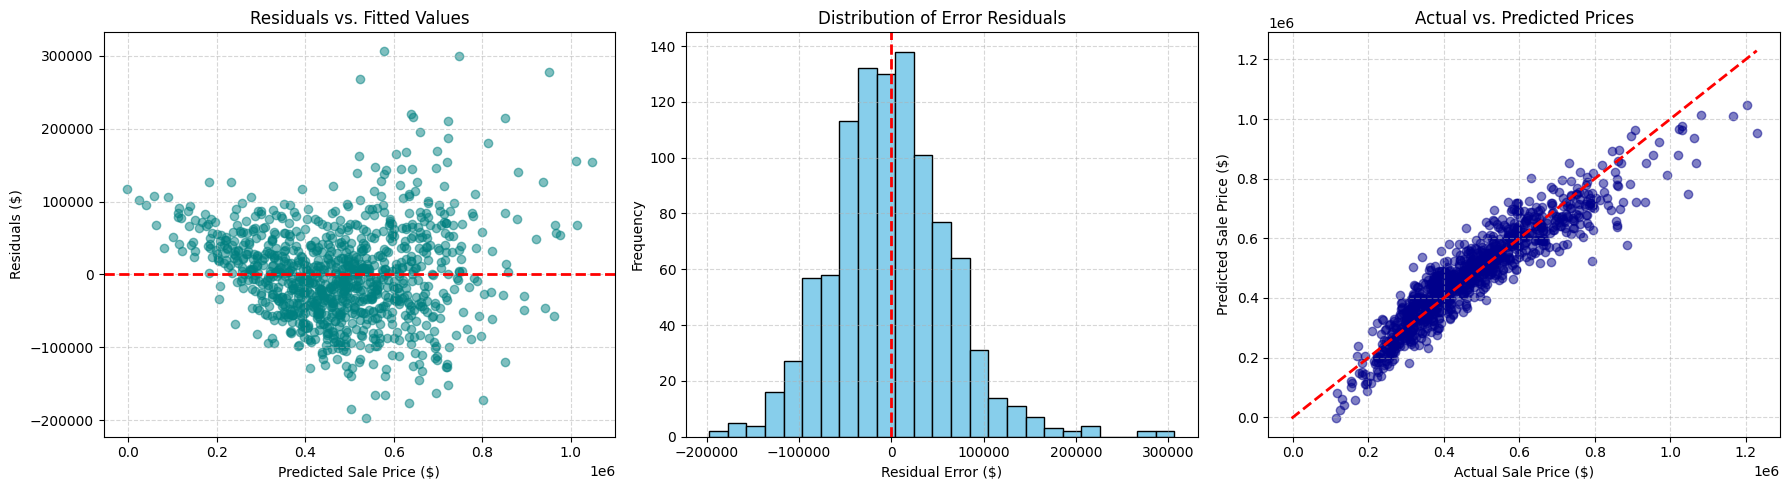

In [ ]:
# Prepare test matrices for the evaluation cases
X_test_all = X_test_clean.values
X_test_sig = X_test_pruned.values
y_test_mat = y_test.reshape(-1, 1)


# 1. Custom Evaluation Function 
def evaluate_model_on_test(X_train_data, y_train_data, X_test_data, y_test_data):
  n_tr = X_train_data.shape[0]
  n_te = X_test_data.shape[0]

  # Add bias column of ones
  X_tr_b = np.hstack([np.ones((n_tr, 1)), X_train_data])
  X_te_b = np.hstack([np.ones((n_te, 1)), X_test_data])

  # Fit OLS via pseudo-inverse
  w = np.linalg.pinv(X_tr_b.T @ X_tr_b) @ X_tr_b.T @ y_train_data

  # Predict on test set
  y_pred = X_te_b @ w
  residuals = y_test_data - y_pred

  # Calculate manual metrics
  mae = np.mean(np.abs(residuals))
  mse = np.mean(residuals**2)
  rmse = math.sqrt(mse)

  # R^2 = 1 - (SS_res / SS_tot)
  ss_res = np.sum(residuals**2)
  ss_tot = np.sum((y_test_data - np.mean(y_test_data)) ** 2)
  r2 = 1.0 - (ss_res / ss_tot)

  return {
      'weights': w,
      'y_pred': y_pred,
      'residuals': residuals,
      'MAE': mae,
      'MSE': mse,
      'RMSE': rmse,
      'R2': r2,
  }


# 2. Run Evaluation for Primary Models
results_all = evaluate_model_on_test(
    X_train_clean.values, y_train_mat, X_test_all, y_test_mat
)
results_sig = evaluate_model_on_test(
    X_train_pruned.values, y_train_mat, X_test_sig, y_test_mat
)

# 3. Present Error Metrics Table
test_metrics_df = pd.DataFrame([
    {
        'Model Configuration': 'All Variables (Case iii)',
        'MAE ($)': results_all['MAE'],
        'MSE': results_all['MSE'],
        'RMSE ($)': results_all['RMSE'],
        'R² Score': results_all['R2'],
    },
    {
        'Model Configuration': 'Significant Variables Only (Case i)',
        'MAE ($)': results_sig['MAE'],
        'MSE': results_sig['MSE'],
        'RMSE ($)': results_sig['RMSE'],
        'R² Score': results_sig['R2'],
    },
])

print('=== HOLD-OUT TEST DATA PERFORMANCE ===')
print(test_metrics_df.to_string(index=False))

# 4. Generate Error Analysis Diagnostic Graphs (Using Best Model: All Variables)
y_pred_best = results_all['y_pred'].flatten()
residuals_best = results_all['residuals'].flatten()
y_actual = y_test_mat.flatten()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Residuals vs. Fitted Values (Homoscedasticity Check)
axes[0].scatter(y_pred_best, residuals_best, alpha=0.5, color='teal')
axes[0].axhline(0, color='red', linestyle='--', linewidth=2)
axes[0].set_title('Residuals vs. Fitted Values')
axes[0].set_xlabel('Predicted Sale Price ($)')
axes[0].set_ylabel('Residuals ($)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Residual Error Distribution (Normality Check)
axes[1].hist(residuals_best, bins=25, color='skyblue', edgecolor='black')
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title('Distribution of Error Residuals')
axes[1].set_xlabel('Residual Error ($)')
axes[1].set_ylabel('Frequency')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Plot 3: Actual vs. Predicted Prices (Linear Alignment Check)
axes[2].scatter(y_actual, y_pred_best, alpha=0.5, color='darkblue')
min_val = min(y_actual.min(), y_pred_best.min())
max_val = max(y_actual.max(), y_pred_best.max())
axes[2].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)
axes[2].set_title('Actual vs. Predicted Prices')
axes[2].set_xlabel('Actual Sale Price ($)')
axes[2].set_ylabel('Predicted Sale Price ($)')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [21]:
X_train_all = X_train_clean.values
X_test_all = X_test_clean.values
y_tr = y_train_mat.ravel()
y_te = y_test_mat.ravel()

# 2. Fit Scikit-Learn Model
sk_model = LinearRegression(fit_intercept=True)
sk_model.fit(X_train_all, y_tr)
y_pred_sk = sk_model.predict(X_test_all)

# Scikit-Learn Metrics
sk_mae = mean_absolute_error(y_te, y_pred_sk)
sk_mse = mean_squared_error(y_te, y_pred_sk)
sk_rmse = math.sqrt(sk_mse)
sk_r2 = r2_score(y_te, y_pred_sk)

# 3. Custom Implementation (From Scratch OLS via Pseudo-Inverse)
X_tr_b = np.hstack([np.ones((len(X_train_all), 1)), X_train_all])
X_te_b = np.hstack([np.ones((len(X_test_all), 1)), X_test_all])

w_custom = np.linalg.pinv(X_tr_b.T @ X_tr_b) @ X_tr_b.T @ y_train_mat
y_pred_custom = (X_te_b @ w_custom).ravel()

# Custom Metrics
res_custom = y_te - y_pred_custom
custom_mae = np.mean(np.abs(res_custom))
custom_mse = np.mean(res_custom**2)
custom_rmse = math.sqrt(custom_mse)
custom_r2 = 1.0 - (
    np.sum(res_custom**2) / np.sum((y_te - np.mean(y_te)) ** 2)
)

# 4. Comparative Results Summary Table
comparison_df = pd.DataFrame({
    'Metric': ['MAE ($)', 'MSE', 'RMSE ($)', 'R² Score', 'Intercept (w0)'],
    'Custom Implementation': [
        custom_mae,
        custom_mse,
        custom_rmse,
        custom_r2,
        w_custom[0].item(),
    ],
    'Scikit-Learn Library': [
        sk_mae,
        sk_mse,
        sk_rmse,
        sk_r2,
        sk_model.intercept_,
    ],
    'Absolute Difference': [
        abs(custom_mae - sk_mae),
        abs(custom_mse - sk_mse),
        abs(custom_rmse - sk_rmse),
        abs(custom_r2 - sk_r2),
        abs(w_custom[0].item() - sk_model.intercept_),
    ],
})

print('=== MODEL COMPARISON: CUSTOM VS SCIKIT-LEARN ===')
print(comparison_df.to_string(index=False))

=== MODEL COMPARISON: CUSTOM VS SCIKIT-LEARN ===
        Metric  Custom Implementation  Scikit-Learn Library  Absolute Difference
       MAE ($)           4.916114e+04          4.916114e+04         1.449589e-07
           MSE           4.107915e+09          4.107915e+09         2.391720e-02
      RMSE ($)           6.409302e+04          6.409302e+04         1.865774e-07
      R² Score           8.646284e-01          8.646284e-01         7.881473e-13
Intercept (w0)           7.522519e+05          7.915692e+05         3.931725e+04


In [25]:

# Predict price for a new house
def predict_price(house):
    # Convert the house into a DataFrame
    new_df = pd.DataFrame([house])

    # Create derived features
    renovation = new_df['renovation_year'].iloc[0]

    new_df['is_renovated'] = int(pd.notna(renovation) and renovation > 0)
    new_df['renovation_year_clean'] = (
        float(renovation) if pd.notna(renovation) else 0.0
    )
    new_df['house_age'] = new_df['sale_year'] - new_df['year_built']

    new_df = new_df.drop(columns=['renovation_year'])

    # Fill missing values using training median
    new_df['lot_size_sqft'] = new_df['lot_size_sqft'].fillna(lot_median)

    # Cap outliers using training limits
    new_df['living_area_sqft'] = np.clip(
        new_df['living_area_sqft'], min_liv, max_liv
    )
    new_df['lot_size_sqft'] = np.clip(
        new_df['lot_size_sqft'], min_lot, max_lot
    )

    # One-hot encoding
    for col in cat_cols:
        for c in sorted(combined[col + '_' + str(c)].unique()) if False else []:
            pass

        for feature in X_train_clean.columns:
            if feature.startswith(col + '_'):
                category = feature[len(col) + 1:]
                new_df[feature] = (new_df[col] == category).astype(int)

    new_df = new_df.drop(columns=cat_cols)

    # Standardize using training statistics
    for col in scale_cols:
        new_df[col] = (new_df[col] - train_means[col]) / train_stds[col]

    # Keep the same features and order as training
    new_df = new_df.reindex(columns=X_train_clean.columns, fill_value=0)

    # Add intercept and predict using custom OLS
    X_new = np.hstack([np.ones((1, 1)), new_df.values])
    prediction = X_new @ weights_ols

    return prediction.item()


# Example new house
new_house = {
    'city': 'Laval',
    'neighborhood': 'Chomedey',
    'property_type': 'Single Family',
    'bedrooms': 3,
    'bathrooms': 2,
    'living_area_sqft': 1500,
    'lot_size_sqft': 5500,
    'year_built': 1995,
    'renovation_year': None,
    'garage': 'Yes',
    'basement': 'Yes',
    'sale_year': 2024
}

print("New house predicted price: $", round(predict_price(new_house), 2))


New house predicted price: $ 607263.52


C:\Users\User\AppData\Local\Temp\ipykernel_12984\3254734016.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  new_df[feature] = (new_df[col] == category).astype(int)
C:\Users\User\AppData\Local\Temp\ipykernel_12984\3254734016.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  new_df[feature] = (new_df[col] == category).astype(int)
C:\Users\User\AppData\Local\Temp\ipykernel_12984\3254734016.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has p

In [24]:

# Test prediction on a real house from the test set

# Find a test house with actual price $259,000
matches = np.where(y_test_mat.flatten() == 259000)[0]

if len(matches) == 0:
    print("No matching house found in the test set.")
else:
    i = matches[0]

    # 1. Single-record prediction
    one_house = X_test_clean.iloc[[i]].values
    one_house = np.hstack([np.ones((1, 1)), one_house])

    single_prediction = (one_house @ weights_ols).item()

    # 2. Batch prediction
    batch_predictions = results_all['y_pred'].flatten()
    batch_prediction = batch_predictions[i]

    # 3. Actual price
    actual_price = y_test_mat[i].item()

    # 4. Prediction error
    error = abs(actual_price - single_prediction)

    print(f"Predicted price (single record)  : ${single_prediction:,.2f}")
    print(f"Predicted price (batch pipeline) : ${batch_prediction:,.2f}")
    print(f"Actual price                     : ${actual_price:,.2f}")
    print(f"Absolute error                   : ${error:,.2f}")


Predicted price (single record)  : $223,197.95
Predicted price (batch pipeline) : $223,197.95
Actual price                     : $259,000.00
Absolute error                   : $35,802.05
